In [1]:
%load_ext autoreload
%autoreload 2

from funkcje.funkcje import *
from funkcje.wskazniki_kredytowe import oblicz_wskazniki
from funkcje.do_pipeline import *

In [121]:
import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score,average_precision_score, roc_auc_score, brier_score_loss, log_loss, roc_curve
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from scipy.special import logit, expit
from scipy.optimize import brentq
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import StratifiedKFold
from scipy.stats import beta
import shap
from sklearn.inspection import partial_dependence, PartialDependenceDisplay
from sklearn.inspection import permutation_importance

In [5]:
#Dane
df = pd.read_csv("zbior_1.csv")
#usuwam wybrane zmienne kategoryczne na podstawie tego co w eksploracja_danych.ipynb
X=df.iloc[:, :-1].drop(columns=["szczegolnaFormaPrawna_Symbol", "schemat_wsk_rzis","schemat_wsk_bilans"])
X=oblicz_wskazniki(X)
y=df.iloc[:, -1]

#Podzil na zbior treningowy (70%) i pozostale
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=2137,
    stratify=y
)

#Podzil na zbior walidacyjny (15%) i testowy (15%)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=2137,
    stratify=y_temp
)

KOL = {"train": "#3E5C76", "valid": "#C9A227", "test": "#A3262C", "logit": "#3E5C76", "black-box": "#A3262C"}
TARGET_PD = 0.04 

# Finalny model regresji

In [9]:

regresja_logistyczna_pipeline = Pipeline([
    ("przygotowanie_cech", PrzygotowanieCech([])),
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegressionUjemne(
        l1_ratio=1, solver="liblinear", C=100, random_state=2137, max_iter=1000
    )),
])

In [10]:
params={'classifier__C': np.float64(0.1),
  'przygotowanie_cech__liczba_kwantyli': np.int64(10),
  'przygotowanie_cech__prog_auc': np.float64(0.55),
  'przygotowanie_cech__prog_korelacji': np.float64(0.7),
  'przygotowanie_cech__prog_monotonicznosci': np.float64(0.1),
  'przygotowanie_cech__prog_nan': np.float64(0.35),
  'przygotowanie_cech__prog_zer': np.float64(0.3),
  'przygotowanie_cech__tylko_wskazniki': np.False_}
regresja_logistyczna = clone(regresja_logistyczna_pipeline)
regresja_logistyczna.set_params(**params)
regresja_logistyczna.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('przygotowanie_cech', ...), ('imputer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,kolumny_do_pominiecia,[]
,prog_korelacji,np.float64(0.7)
,prog_auc,np.float64(0.55)
,prog_nan,np.float64(0.35)
,prog_zer,np.float64(0.3)


In [11]:
betas = regresja_logistyczna.named_steps["classifier"].coef_[0]

In [12]:
#liczb niezerowych bet
np.sum(betas != 0)

np.int64(15)

In [13]:
#liczba dodatnich bet
np.sum(betas>0)

np.int64(0)

In [14]:
P = {"logit": {s: regresja_logistyczna.predict_proba(X)[:, 1] for s, X in [("train", X_train), ("valid", X_valid), ("test", X_test)]}}
print(f"AUC na zbiorze walidacyjnym: {roc_auc_score(y_valid, P['logit']['valid'])}")
print(f"AUC na zbiorze testowym: {roc_auc_score(y_test, P['logit']['test'])}")

AUC na zbiorze walidacyjnym: 0.8060975609756098
AUC na zbiorze testowym: 0.7806475762680142


In [126]:
#Wypisanie nazw cech, które mają niezerowe współczynniki i ich współczynniki
kolumny_wynikowe = regresja_logistyczna.named_steps["przygotowanie_cech"].kolumny_wynikowe_
kolumny_niezerowe = [kolumny_wynikowe[i] for i in range(len(betas)) if betas[i] != 0]
betas_niezerowe = [betas[i] for i in range(len(betas)) if betas[i] != 0]
print("Cechy z niezerowymi współczynnikami:")
for i, kolumna in enumerate(kolumny_niezerowe):
    print(f"{kolumna}: {betas_niezerowe[i]}")

Cechy z niezerowymi współczynnikami:
-wsk_index_skr_zaw: -0.33866186753142863
-wsk_index_nowe: -0.2956302918937439
wsk_akt_generowania_got_1: -0.14642682537039303
wsk_marza_ebitda_2: -0.03239669762917381
wsk_rent_kapitalu: -0.02367825221631957
wsk_zysk_operacyjny_zob_1: -0.010290587725583155
wsk_ebitda_zobowiazan_3: -0.01548353359234864
wsk_kredyt_zobowiazania_ebitda: -0.03487389552457176
-Aktywa_spadek: -0.37930162783663823
-wsk_pokrycie_aktywow_tr_kapitalem_st_wzrost: -0.08626747340822327
-wsk_ebitda_zobowiazan_odsetki_4_spadek: -0.28128052029063655
-wsk_cykl_konwersji_gotowki_wzrost: -0.00198234341336968
-wsk_zadluzenia_wzrost: -0.3747985664063848
-wsk_fin_majatku_kapitalem_spadek: -0.016037292521060176
wsk_fin_majatku_kapitalem_wzrost: -0.11163620050088924


# Finalny model black-box

In [22]:
xgboost_pipeline=Pipeline([
    ("przygotowanie_cech", PrzygotowanieCech_xgb()),
    ("classifier", XGBClassifier(
        enable_categorical=True,
        tree_method="hist",
        random_state=2137)
    )
])
prams_xgb={'classifier__colsample_bytree': 1.0, 'classifier__gamma': 1, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__min_child_weight': 3, 'classifier__n_estimators': 400, 'classifier__reg_alpha': 1, 'classifier__reg_lambda': 10, 'classifier__subsample': 1.0, 'przygotowanie_cech__prog_korelacji': 0.7, 'przygotowanie_cech__prog_nan': 0.25, 'przygotowanie_cech__prog_zer': 0.3, 'przygotowanie_cech__uwzglednij_kategoryczne': False}

In [23]:
black_box = clone(xgboost_pipeline)
black_box.set_params(**prams_xgb)
black_box.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('przygotowanie_cech', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,prog_korelacji,0.7
,prog_nan,0.25
,prog_zer,0.3
,uwzglednij_kategoryczne,False
,kolumny_do_pominiecia,None


In [24]:
P["black-box"] = {s: black_box.predict_proba(X)[:, 1] for s, X in [("train", X_train), ("valid", X_valid), ("test", X_test)]}

print(f"AUC na zbiorze walidacyjnym: {roc_auc_score(y_valid, P['black-box']['valid'])}")
print(f"AUC na zbiorze testowym: {roc_auc_score(y_test, P['black-box']['test'])}")

AUC na zbiorze walidacyjnym: 0.8396951219512194
AUC na zbiorze testowym: 0.7958075987273068


# Kalibraja

### Funkcja z laboratoriów

In [150]:
def h_statistic(f, X, j, k):
    """H Friedmana dla pary (j, k): wycentrowane funkcje częściowej zależności liczone w punktach próby X."""
    n, Xr = len(X), X.reset_index(drop=True)
    duza = pd.concat([Xr] * n, ignore_index=True)               # blok i: cała próba, cechy z koalicji z wiersza i
    def czesciowa(cechy):
        B = duza.copy()
        for c in cechy:
            B[c] = np.repeat(Xr[c].to_numpy(), n)
        v = np.asarray(f(B)).reshape(n, n).mean(axis=1)
        return v - v.mean()
    pjk, pj, pk = czesciowa([j, k]), czesciowa([j]), czesciowa([k])
    reszta = pjk - pj - pk
    return float(np.sqrt(np.sum(reszta ** 2) / np.sum(pjk ** 2))), float(np.sqrt(np.mean(reszta ** 2)))

#Do oceny przed kalibracja
EPS=1e-6
def ks(y, p):
    fpr, tpr, _ = roc_curve(y, p)
    return float(np.max(tpr - fpr))
def reliability(ax, y_true, p, label, n_bins=10, **kw):
    obs, pred = calibration_curve(y_true, p, n_bins=n_bins, strategy="quantile")
    ax.plot(pred, obs, marker="o", label=label, **kw)

def os_log(ax, lo=2e-3, hi=1.0):
    ax.plot([lo, hi], [lo, hi], "--", color="gray", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("średnie PD w przedziale"); ax.set_ylabel("obserwowany DR"); ax.grid(alpha=0.3, which="both")
    
def raport_kalibracji(y_true, modele, tytul="Kalibracja na zbiorze testowym"):
    # modele: słownik {nazwa: PD}; zwraca tabelę miar i rysuje reliability diagram
    y_true = np.asarray(y_true)
    tab_r = pd.DataFrame({k: miary(y_true, np.asarray(v)) for k, v in modele.items()}).T
    tab_r.insert(0, "DR", y_true.mean())
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for k, v in modele.items():
        reliability(axes[0], y_true, np.asarray(v), k)
        axes[1].hist(np.asarray(v), bins=np.logspace(-3.5, 0, 50), histtype="step", lw=2, label=k)
    os_log(axes[0]); axes[0].set_title(tytul); axes[0].legend()
    axes[1].set_xscale("log"); axes[1].set_xlabel("PD"); axes[1].set_title("Rozkład PD"); axes[1].legend()
    plt.tight_layout(); plt.show()
    return tab_r

def ece(y_true, p, n_bins=10):
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, edges[1:-1]), 0, n_bins - 1)
    return float(sum(np.mean(idx == m) * abs(y_true[idx == m].mean() - p[idx == m].mean())
                     for m in range(n_bins) if np.any(idx == m)))

def przedzialy_rowne_liczebnie(p, n_bins=10):
    edges = np.unique(np.quantile(p, np.linspace(0, 1, n_bins + 1)))
    return np.clip(np.digitize(p, edges[1:-1], right=True), 0, len(edges) - 2), len(edges) - 1

def ace(y_true, p, n_bins=10):
    idx, k = przedzialy_rowne_liczebnie(p, n_bins)
    return float(sum(np.mean(idx == m) * abs(y_true[idx == m].mean() - p[idx == m].mean()) for m in range(k) if np.any(idx == m)))

def murphy(y_true, p, n_bins=10):
    idx, k = przedzialy_rowne_liczebnie(p, n_bins)
    o = y_true.mean(); rel = res = 0.0
    for m in range(k):
        msk = idx == m
        if msk.any():
            w = msk.mean(); rel += w * (p[msk].mean() - y_true[msk].mean()) ** 2; res += w * (y_true[msk].mean() - o) ** 2
    return rel, res, o * (1 - o)

def cox(y_true, p):
    z = logit(np.clip(p, EPS, 1 - EPS))
    a = brentq(lambda d: expit(z + d).mean() - y_true.mean(), -15, 15)        # wyraz wolny przy nachyleniu = 1
    if np.ptp(z) < 1e-9:                                                       # stałe PD - nachylenie nieokreślone
        return a, np.nan
    b = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y_true).coef_[0, 0]
    return a, b

def miary(y_true, p):
    y_true = np.asarray(y_true); p = np.asarray(p); a, b = cox(y_true, p)
    return {"średnie PD": p.mean(), "AUC": roc_auc_score(y_true, p), "Brier": brier_score_loss(y_true, p),
            "log-loss": log_loss(y_true, np.clip(p, EPS, 1 - EPS)), "ECE": ece(y_true, p), "ACE": ace(y_true, p),
            "CITL a": a, "nachylenie b": b}


def metryki(y, p):
    y, p = np.asarray(y), np.asarray(p); auc = roc_auc_score(y, p)
    return {"n": len(y), "DR": y.mean(), "średnie PD": p.mean(), "AUC": auc, "Gini": 2 * auc - 1, "KS": ks(y, p),
            "PR-AUC": average_precision_score(y, p), "log-loss": log_loss(y, np.clip(p, EPS, 1 - EPS)),
            "Brier": brier_score_loss(y, p), "ECE": ece(y, p), "ACE": ace(y, p)}

#Do kalibracji krztałtu

def _z(p):
    return logit(np.clip(p, EPS, 1 - EPS))

def _beta_cechy(p):
    p = np.clip(p, EPS, 1 - EPS); return np.column_stack([np.log(p), -np.log(1 - p)])

FIT = {
    "bez kalibracji": lambda y, p: None,
    "Platt": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_z(p).reshape(-1, 1), y),
    "izotoniczna": lambda y, p: IsotonicRegression(out_of_bounds="clip", y_min=EPS, y_max=1 - EPS).fit(p, y),
    "beta": lambda y, p: LogisticRegression(C=1e6, max_iter=1000).fit(_beta_cechy(p), y),
}

def zastosuj(metoda, kal, p):
    if metoda == "bez kalibracji":
        return np.asarray(p)
    if metoda == "Platt":
        return kal.predict_proba(_z(p).reshape(-1, 1))[:, 1]
    if metoda == "beta":
        return kal.predict_proba(_beta_cechy(p))[:, 1]
    return kal.predict(p)

def cv_logloss(metoda, y, p, k=5):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=2137); ll = []
    for a, b in skf.split(p.reshape(-1, 1), y):
        q = zastosuj(metoda, FIT[metoda](y[a], p[a]), p[b])
        ll.append(log_loss(y[b], np.clip(q, EPS, 1 - EPS)))
    return float(np.mean(ll))

#zmodyfikowane by działało
def cv_logloss(metoda, y, p, k=5):
    y = np.asarray(y)
    p = np.asarray(p)

    skf = StratifiedKFold(
        n_splits=k,
        shuffle=True,
        random_state=2137
    )
    ll = []

    for a, b in skf.split(p.reshape(-1, 1), y):
        q = zastosuj(metoda, FIT[metoda](y[a], p[a]), p[b])
        ll.append(log_loss(y[b], np.clip(q, EPS, 1 - EPS)))

    return float(np.mean(ll))

#Do kalibracji poziomu
def delta_do_sredniej(p, cel, lo=-15.0, hi=15.0, iters=100):
    z = _z(p)
    for _ in range(iters):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if expit(z + mid).mean() < cel else (lo, mid)
    return (lo + hi) / 2

## Diagnostyka przed klibracją

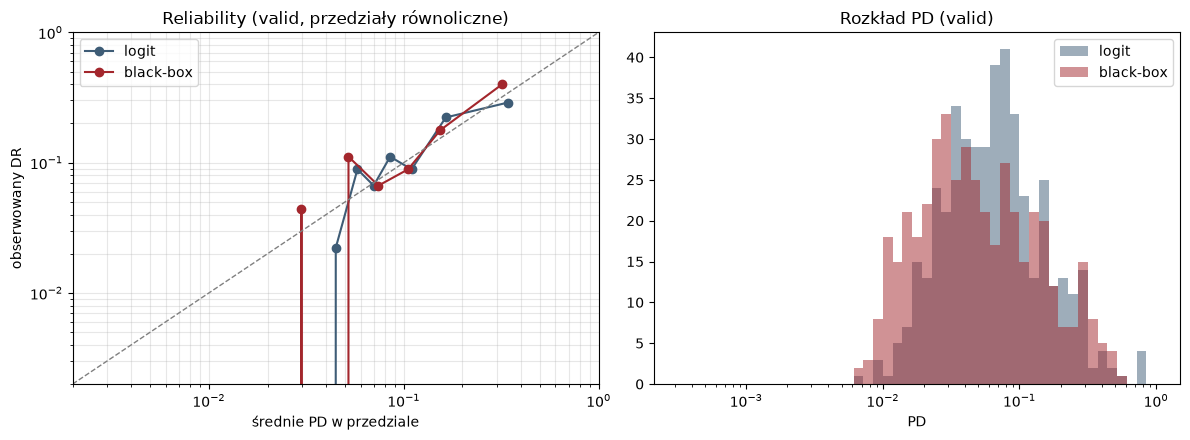

,DR,średnie PD,Brier,ECE,ACE,log-loss
logit,0.0889,0.0951,0.0704,0.0215,0.0292,0.2482
black-box,0.0889,0.0826,0.0667,0.0154,0.0291,0.2327


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for m in ["logit", "black-box"]:
    reliability(axes[0], y_valid, P[m]["valid"], m, color=KOL[m])
    axes[1].hist(P[m]["valid"], bins=np.logspace(-3.5, 0, 50), alpha=0.5, label=m, color=KOL[m])
os_log(axes[0]); axes[0].set_title("Reliability (valid, przedziały równoliczne)"); axes[0].legend()
axes[1].set_xscale("log"); axes[1].set_xlabel("PD"); axes[1].set_title("Rozkład PD (valid)"); axes[1].legend()
plt.tight_layout(); plt.show()
display(pd.DataFrame({m: metryki(y_valid, P[m]["valid"]) for m in ["logit", "black-box"]}).T[["DR", "średnie PD", "Brier", "ECE", "ACE", "log-loss"]].round(4))

## Kalibracja krztałtu

In [27]:
wybor = pd.DataFrame({m: {met: cv_logloss(met, y_valid, P[m]["valid"]) for met in FIT} for m in ["logit", "black-box"]}).T
display(wybor.round(5))

,bez kalibracji,Platt,izotoniczna,beta
logit,0.24817,0.25060,0.28765,0.25541
black-box,0.23274,0.23339,0.30365,0.23597


Czyli black-box i regresja logistyczna nie wymagają kalibracji krztałtu.

## Kalibracja poziomu

In [30]:
P_kalibr = {}

for MODEL in ["logit", "black-box"]:
    PS = {s: np.asarray(P[MODEL][s]) for s in ["train", "valid", "test"]}
    DELTA = delta_do_sredniej(PS["valid"], TARGET_PD)
    P_kalibr[MODEL] = {s: expit(_z(PS[s]) + DELTA) for s in PS}

    print(f"Model: {MODEL}, kalibracja: bez kalibracji, δ = {DELTA:+.3f}")
    print(f"Średnie PD na valid: {P[MODEL]['valid'].mean():.2%} (model) -> {P_kalibr[MODEL]['valid'].mean():.2%} (po δ)")

    wiersze_kal = {"test - model bez kalibracji": metryki(y_test, P[MODEL]["test"])}
    wiersze_kal["test + przesunięcie do 4%"] = metryki(y_test, P_kalibr[MODEL]["test"])

    tab_kal = pd.DataFrame(wiersze_kal).T[["DR", "średnie PD", "AUC", "Brier", "ECE", "ACE", "log-loss"]]
    display(tab_kal.round(4))

Model: logit, kalibracja: bez kalibracji, δ = -1.045
Średnie PD na valid: 9.51% (model) -> 4.00% (po δ)


,DR,średnie PD,AUC,Brier,ECE,ACE,log-loss
test - model bez kalibracji,0.0867,0.0988,0.7806,0.0721,0.0423,0.0299,0.2567
test + przesunięcie do 4%,0.0867,0.0411,0.7806,0.0762,0.0527,0.0513,0.2780


Model: black-box, kalibracja: bez kalibracji, δ = -0.848
Średnie PD na valid: 8.26% (model) -> 4.00% (po δ)


,DR,średnie PD,AUC,Brier,ECE,ACE,log-loss
test - model bez kalibracji,0.0867,0.088,0.7958,0.0629,0.0283,0.0403,0.2333
test + przesunięcie do 4%,0.0867,0.043,0.7958,0.0688,0.0436,0.0568,0.2531


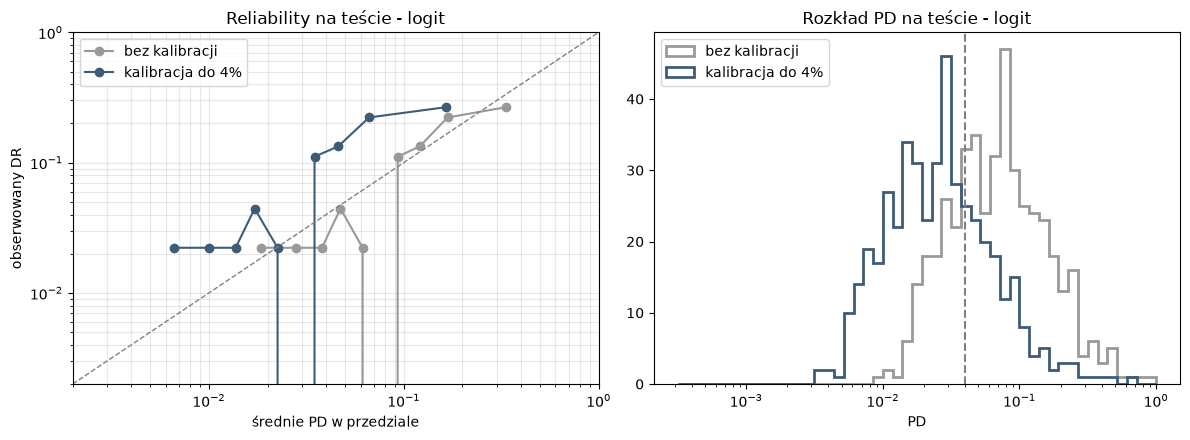

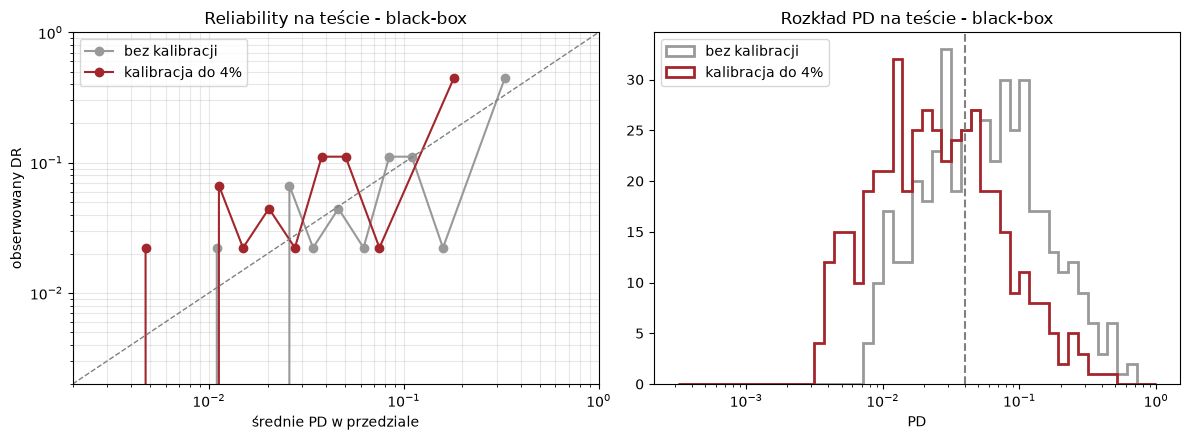

In [43]:
for MODEL in ["logit", "black-box"]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    serie = [
        (P[MODEL]["test"], "bez kalibracji", "#999999"),
        (P_kalibr[MODEL]["test"], "kalibracja do 4%", KOL[MODEL])
    ]

    for p, lab, col in serie:
        reliability(axes[0], y_test, p, lab, color=col)
        axes[1].hist(
            p, bins=np.logspace(-3.5, 0, 50),
            histtype="step", lw=2, label=lab, color=col
        )

    os_log(axes[0])
    axes[0].set_title(f"Reliability na teście - {MODEL}")
    axes[0].legend()

    axes[1].set_xscale("log")
    axes[1].axvline(TARGET_PD, ls="--", color="gray")
    axes[1].set_xlabel("PD")
    axes[1].set_title(f"Rozkład PD na teście - {MODEL}")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

# Rating

In [46]:
#Wartosci z wykladu
RATING_BINS = [0.00, 0.01, 0.02, 0.05, 0.08, 0.12, 0.20, 1.0 + 1e-9]
RATING_LABELS = ["AAA", "AA", "A", "BBB", "BB", "B", "CCC"]
PD_klasy=[0.005, 0.015, 0.035, 0.065, 0.10, 0.16, 0.30]

## Udział kilentów w klasach

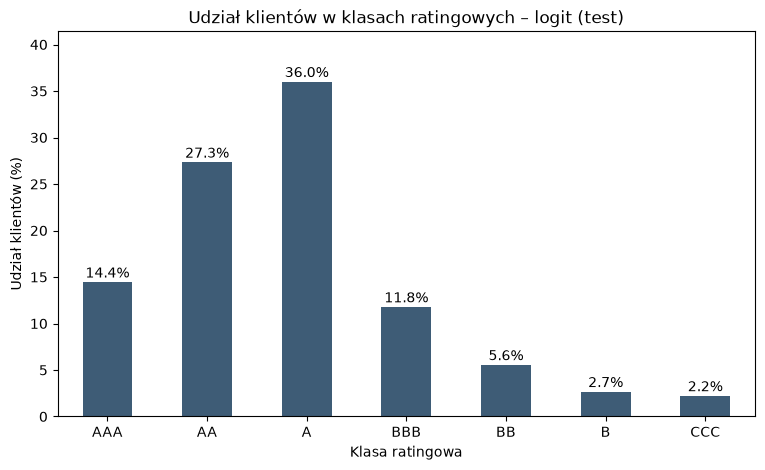

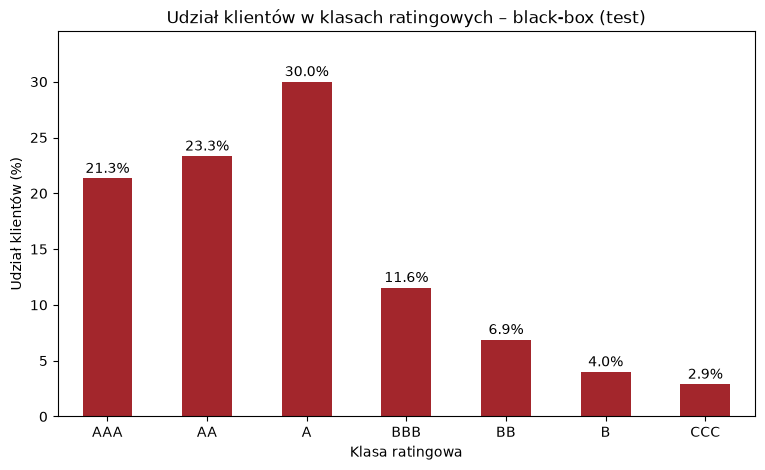

In [45]:
for MODEL in ["logit", "black-box"]:
    prob = P_kalibr[MODEL]["test"]

    udzialy = (
        pd.Series(pd.cut(prob, bins=RATING_BINS, labels=RATING_LABELS, right=False))
        .value_counts(normalize=True)
        .reindex(RATING_LABELS)
        .fillna(0)
    )

    ax = (100 * udzialy).plot.bar(figsize=(9, 5), rot=0, color=KOL[MODEL])

    ax.set_title(f"Udział klientów w klasach ratingowych – {MODEL} (test)" )
    ax.set_xlabel("Klasa ratingowa")
    ax.set_ylabel("Udział klientów (%)")

    for i, v in enumerate(100 * udzialy):
        ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")

    ax.set_ylim(0, max(100 * udzialy) * 1.15)
    plt.show()


## Back test

In [50]:
def swiatlo(p):
    return "zielone" if p >= 0.05 else ("żółte" if p >= 0.01 else "czerwone")


def backtest_jeffreysa(y, prob, prob_przed, rating_bins, rating_labels, pd_klasy):
    y = np.asarray(y)
    prob = np.asarray(prob)
    prob_przed = np.asarray(prob_przed)

    rating = pd.cut(
        prob,
        bins=rating_bins,
        labels=rating_labels,
        right=False
    )

    wyniki = []

    for klasa, pd_ref in zip(rating_labels, pd_klasy):
        maska = np.asarray(rating == klasa)
        n = int(maska.sum())

        if n == 0:
            continue

        d = int(y[maska].sum())
        dr = d / n

        srednie_pd = float(prob[maska].mean())
        srednie_pd_przed = float(prob_przed[maska].mean())

        a = d + 0.5
        b = n - d + 0.5

        p_jeffreysa = float(beta.cdf(srednie_pd, a, b))
        p_jeffreysa_przed = float(beta.cdf(srednie_pd_przed, a, b))

        wyniki.append({
            "Klasa": klasa,
            "n": n,
            "defaulty": d,
            "oczekiwane": n * srednie_pd,
            "PD reprezentatywne": pd_ref,
            "średnie PD": srednie_pd,
            "PD przed kalibracją": srednie_pd_przed,
            "DR": dr,
            "p Jeffreysa": p_jeffreysa,
            "światło": swiatlo(p_jeffreysa),
            "p Jeffreysa przed": p_jeffreysa_przed,
            "światło przed": swiatlo(p_jeffreysa_przed)
        })

    return pd.DataFrame(wyniki).set_index("Klasa")


Model: logit


,n,defaulty,oczekiwane,PD reprezentatywne,średnie PD,PD przed kalibracją,DR,p Jeffreysa,światło,p Jeffreysa przed,światło przed
Klasa,,,,,,,,,,,
AAA,65,2,0.4791,0.005,0.0074,0.0207,0.0308,0.0335,żółte,0.2514,zielone
AA,123,3,1.8181,0.015,0.0148,0.0409,0.0244,0.1783,zielone,0.8205,zielone
A,162,10,5.2505,0.035,0.0324,0.0867,0.0617,0.0261,żółte,0.8738,zielone
BBB,53,11,3.3465,0.065,0.0631,0.1606,0.2075,0.0002,czerwone,0.1739,zielone
BB,25,4,2.4241,0.100,0.0970,0.2336,0.1600,0.1430,zielone,0.8049,zielone
B,12,3,1.8146,0.160,0.1512,0.3350,0.2500,0.1653,zielone,0.7252,zielone
CCC,10,6,3.3622,0.300,0.3362,0.5671,0.6000,0.0424,żółte,0.4232,zielone


Światła po kalibracji: {'żółte': 3, 'zielone': 3, 'czerwone': 1}
Światła przed kalibracją: {'zielone': 7}
DR rośnie monotonicznie: False


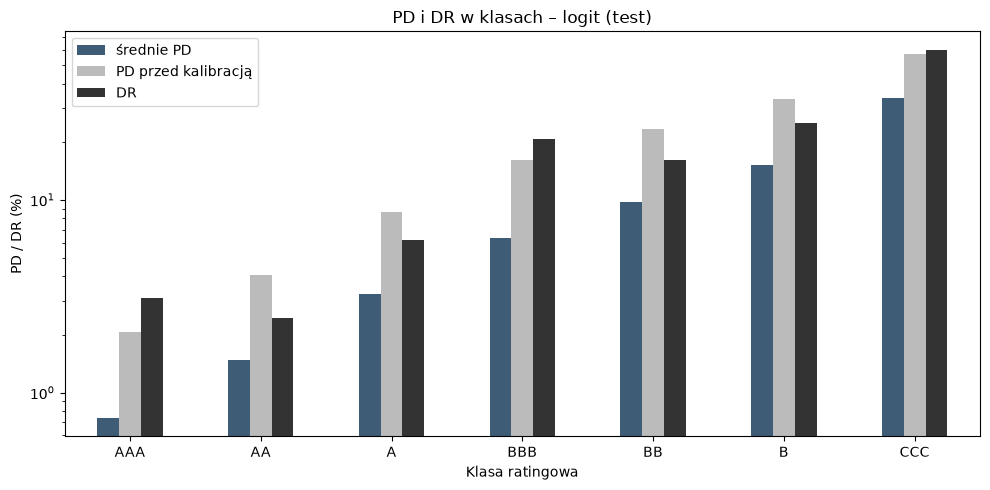


Model: black-box


,n,defaulty,oczekiwane,PD reprezentatywne,średnie PD,PD przed kalibracją,DR,p Jeffreysa,światło,p Jeffreysa przed,światło przed
Klasa,,,,,,,,,,,
AAA,96,1,0.6266,0.005,0.0065,0.0151,0.0104,0.2599,zielone,0.5946,zielone
AA,105,5,1.5176,0.015,0.0145,0.0331,0.0476,0.0092,czerwone,0.1937,zielone
A,135,9,4.4456,0.035,0.0329,0.0734,0.0667,0.0226,żółte,0.6014,zielone
BBB,52,4,3.1793,0.065,0.0611,0.1318,0.0769,0.2943,zielone,0.8843,zielone
BB,31,2,3.0439,0.100,0.0982,0.2023,0.0645,0.7173,zielone,0.9821,zielone
B,18,9,2.8132,0.160,0.1563,0.3012,0.5000,0.0003,czerwone,0.0371,żółte
CCC,13,9,3.7459,0.300,0.2881,0.4802,0.6923,0.0012,czerwone,0.0619,zielone


Światła po kalibracji: {'zielone': 3, 'czerwone': 3, 'żółte': 1}
Światła przed kalibracją: {'zielone': 6, 'żółte': 1}
DR rośnie monotonicznie: False


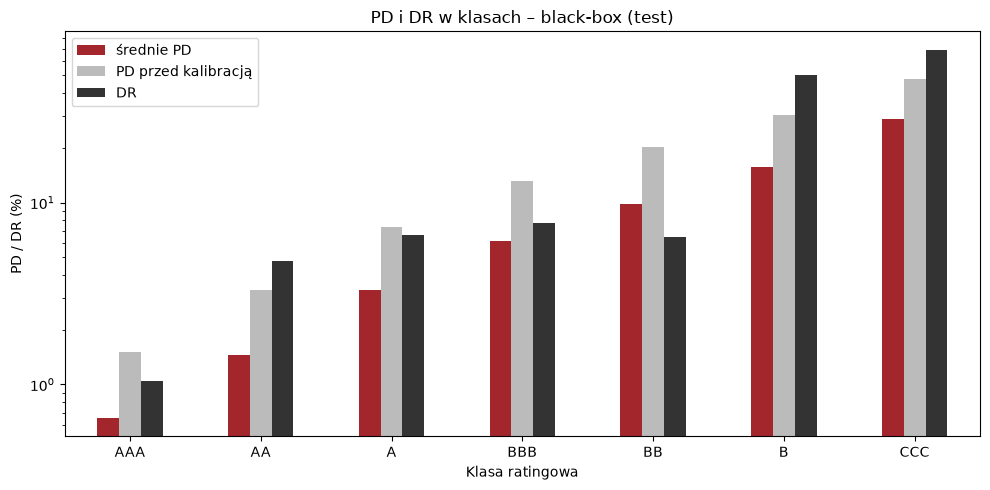

In [51]:
for MODEL in ["logit", "black-box"]:
    prob = P_kalibr[MODEL]["test"]
    prob_przed = P[MODEL]["test"]

    bt = backtest_jeffreysa(
        y_test,
        prob,
        prob_przed,
        RATING_BINS,
        RATING_LABELS,
        PD_klasy
    )

    print(f"\nModel: {MODEL}")
    display(bt.round(4))

    print("Światła po kalibracji:", bt["światło"].value_counts().to_dict())
    print("Światła przed kalibracją:", bt["światło przed"].value_counts().to_dict())

    print(
        "DR rośnie monotonicznie:",
        bool(np.all(np.diff(bt["DR"].to_numpy()) >= 0))
    )

    ax = (100 * bt[
        ["średnie PD", "PD przed kalibracją", "DR"]
    ]).plot.bar(
        figsize=(10, 5),
        rot=0,
        color=[KOL[MODEL], "#BBBBBB", "#333333"]
    )

    ax.set_yscale("log")
    ax.set_xlabel("Klasa ratingowa")
    ax.set_ylabel("PD / DR (%)")
    ax.set_title(f"PD i DR w klasach – {MODEL} (test)")

    plt.tight_layout()
    plt.show()

# SHAP

In [115]:
# Wyciągnięcie wytrenowanego modelu
model = black_box.named_steps["classifier"]

# Przekształcenie danych przez wcześniejsze etapy pipeline
X_transformed = black_box[:-1].transform(X_test)

#nazwy kolumn
feature_names=black_box.named_steps["przygotowanie_cech"].kolumny_wynikowe_

X_transformed = pd.DataFrame(
    X_transformed,
    columns=feature_names,
    index=X_test.index
)

#obliczenie wartości SHAP
explainer = shap.TreeExplainer(model)
shap_values = explainer(X_transformed)

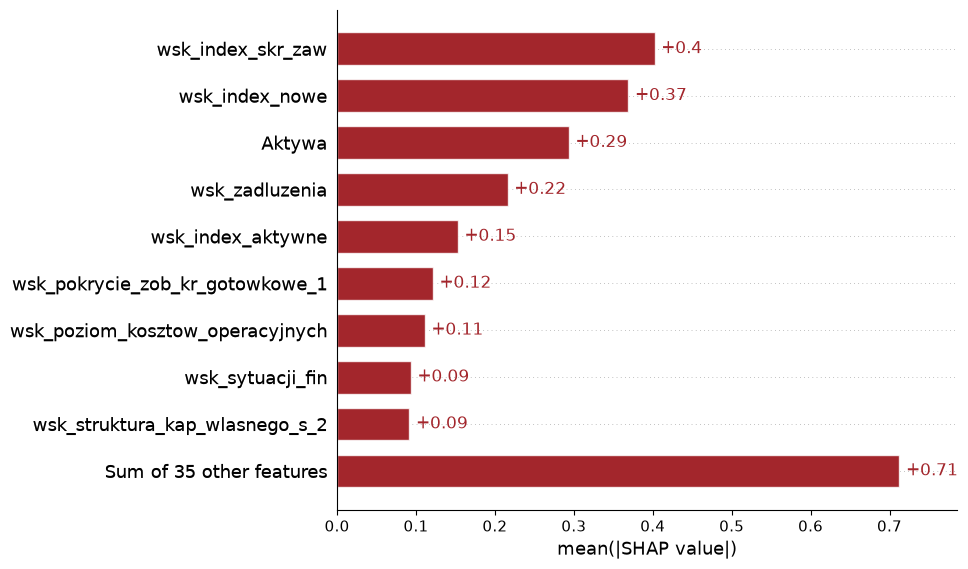

In [133]:
ax = shap.plots.bar(shap_values, show=False)

for bar in ax.patches:
    bar.set_facecolor(KOL["black-box"])
for txt in ax.texts:
    txt.set_color(KOL["black-box"])

plt.show()

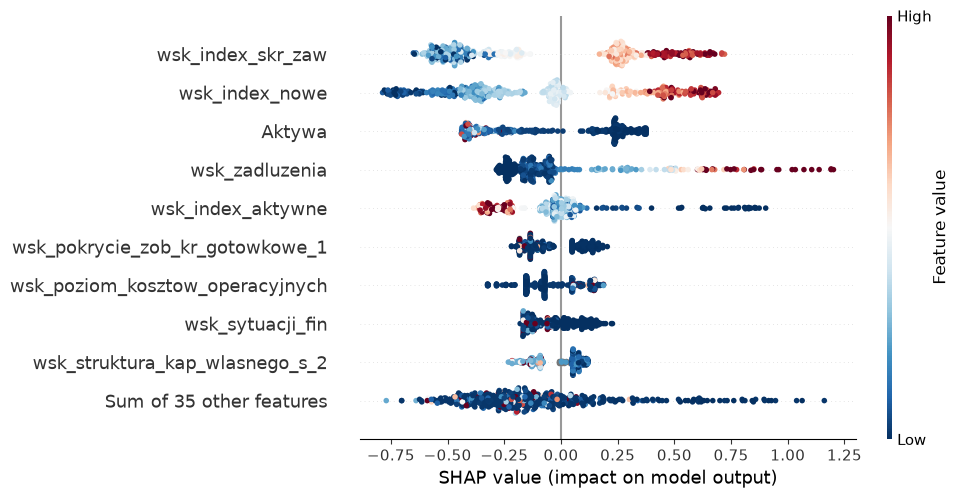

In [134]:
shap.plots.beeswarm(
    shap_values,
    color=plt.get_cmap("RdBu_r")
)

## Interakcje

In [118]:
# SHAP Interaction Values
interaction_values = np.asarray(
    explainer.shap_interaction_values(X_transformed)
)

# Średnia bezwzględna siła interakcji
sila_interakcji = np.abs(interaction_values).mean(axis=0)

# Usunięcie efektów głównych
np.fill_diagonal(sila_interakcji, 0)

# Ranking wszystkich par cech
ranking = []

for i in range(len(feature_names)):
    for j in range(i + 1, len(feature_names)):
        ranking.append({
            "Cecha 1": feature_names[i],
            "Cecha 2": feature_names[j],
            "Siła interakcji": sila_interakcji[i, j]
        })

ranking = (
    pd.DataFrame(ranking)
    .sort_values("Siła interakcji", ascending=False)
    .reset_index(drop=True)
)

# 5 najsilniejszych interakcji
top5 = ranking.head(5)

display(top5)


,Cecha 1,Cecha 2,Siła interakcji
0,wsk_index_skr_zaw,wsk_poziom_kosztow_operacyjnych,0.038698
1,wsk_index_aktywne,wsk_index_nowe,0.033735
2,Aktywa,wsk_zadluzenia,0.029439
3,wsk_poziom_kosztow_operacyjnych,wsk_zadluzenia,0.027767
4,Aktywa,wsk_pokrycie_zob_kr_gotowkowe_1,0.023204


# PDP

## Średnie PD

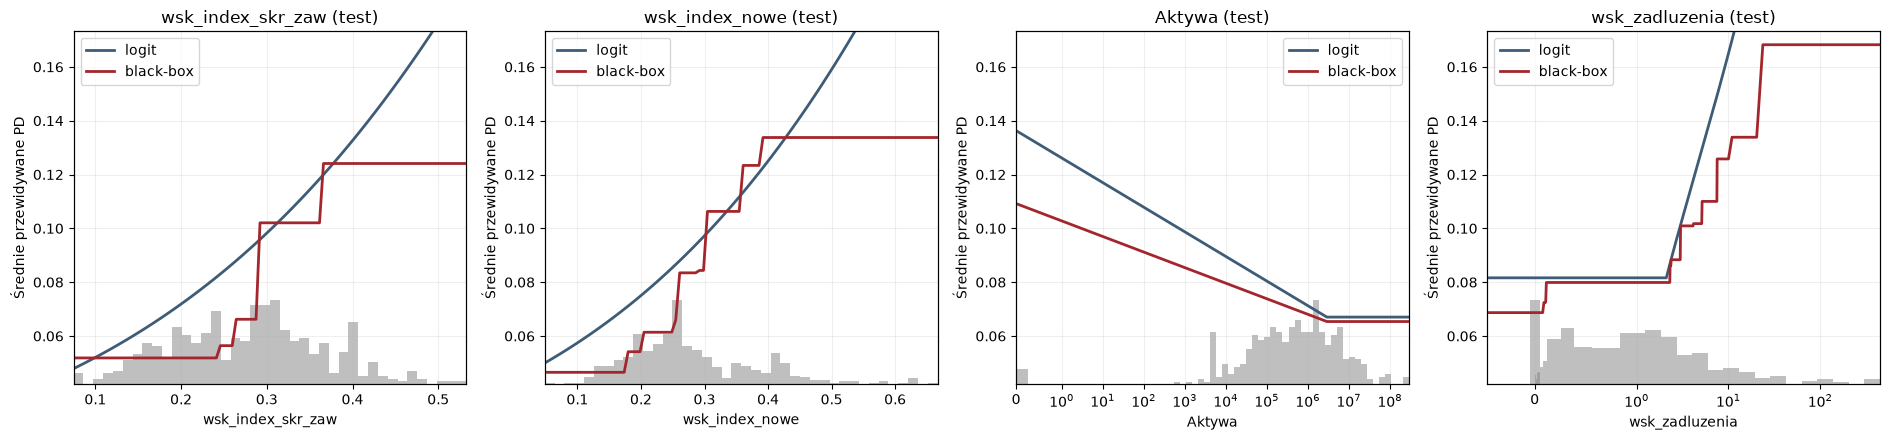

In [102]:
CECHY = ["wsk_index_skr_zaw", "wsk_index_nowe", "Aktywa", "wsk_zadluzenia"]

MODELE = {
    "logit": regresja_logistyczna,
    "black-box": black_box
}

# Pobranie progów funkcji zawiasowej
przygotowanie = regresja_logistyczna.named_steps["przygotowanie_cech"]
kolumny, informacje = przygotowanie.kolumny_niemonotoniczne_

progi_zadluzenia = []

for kolumna, informacja in zip(kolumny, informacje):
    if kolumna == "wsk_zadluzenia":
        progi_zadluzenia = [
            float(informacja[1]),
            float(informacja[2])
        ]
        break

# Własna siatka dla wsk_zadluzenia
x_zad = X_test["wsk_zadluzenia"].dropna()
x_dodatnie = x_zad[x_zad > 0]

siatka = [
    np.geomspace(x_dodatnie.min(), x_dodatnie.max(), 100),
    np.linspace(x_zad.min(), min(10, x_zad.max()), 200),
]

for prog in progi_zadluzenia:
    if x_zad.min() <= prog <= x_zad.max():
        siatka.append(
            np.linspace(
                max(x_zad.min(), prog - 1),
                min(x_zad.max(), prog + 1),
                100
            )
        )

siatka_zad = np.unique(np.concatenate(siatka))
siatka_zad = np.unique(np.concatenate((
    siatka_zad,
    [x_zad.min(), x_zad.max()],
    [p for p in progi_zadluzenia if x_zad.min() <= p <= x_zad.max()]
)))

fig, axes = plt.subplots(1, 4, figsize=(19, 4.5))

# PDP dla obu modeli
displays = {}
indeks_zad = X_test.columns.get_loc("wsk_zadluzenia")

for i, (nazwa, model) in enumerate(MODELE.items()):
    disp = PartialDependenceDisplay.from_estimator(
        estimator=model,
        X=X_test,
        features=CECHY,
        ax=axes if i == 0 else displays["logit"].axes_,
        kind="average",
        method="brute",
        response_method="predict_proba",
        grid_resolution=100,
        percentiles=(0, 1),
        custom_values={indeks_zad: siatka_zad},
        line_kw={
            "label": nazwa,
            "color": KOL[nazwa],
            "linewidth": 2
        }
    )

    displays[nazwa] = disp


    # Ukrycie automatycznych kresek decyli
    for line in disp.deciles_vlines_.ravel():
        if line is not None:
            line.set_visible(False)

# Formatowanie wykresów i histogramy
for ax, cecha in zip(axes, CECHY):
    x = X_test[cecha].dropna()

    ax.set_title(cecha+" (test)")
    ax.set_xlabel(cecha)
    ax.grid(alpha=0.2)
    ax.legend()
    ax.set_xlim(x.min(), x.max())

    ax2 = ax.twinx()

    if cecha in ["Aktywa", "wsk_zadluzenia"]:
        x_dodatnie = x[x > 0]
        n_zer = (x == 0).sum()

        bins = np.geomspace(
            x_dodatnie.min(),
            x_dodatnie.max(),
            40
        )

        ax2.hist(
            x_dodatnie,
            bins=bins,
            color="gray",
            alpha=0.5
        )

        if n_zer > 0:
            szerokosc = 0.5 if cecha == "Aktywa" else 0.1

            ax2.bar(
                0,
                n_zer,
                width=szerokosc,
                color="gray",
                alpha=0.5
            )

        ax.set_xscale("symlog", linthresh=1)

    else:
        ax2.hist(
            x,
            bins=40,
            color="gray",
            alpha=0.5
        )

    # Histogram w dolnej części wykresu
    ax2.set_ylim(0, ax2.get_ylim()[1] * 4)
    ax2.set_yticks([])

    # Krzywe PDP na wierzchu
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)

    ax.set_ylabel("Średnie przewidywane PD")

plt.tight_layout()
plt.show()

## log-szansa

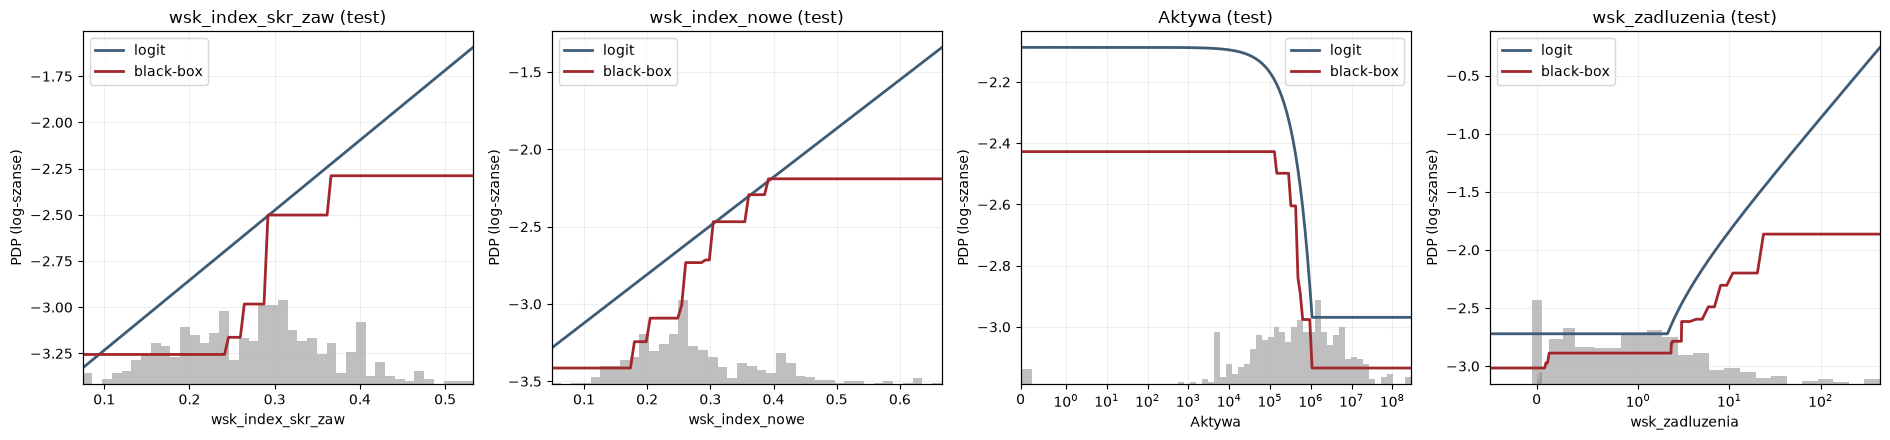

In [103]:


CECHY = [
    "wsk_index_skr_zaw",
    "wsk_index_nowe",
    "Aktywa",
    "wsk_zadluzenia"
]

MODELE = {
    "logit": regresja_logistyczna,
    "black-box": black_box
}


def pdp_log_szanse(model, X, cecha, siatka):
    wyniki = []

    for wartosc in siatka:
        X_temp = X.copy()
        X_temp[cecha] = wartosc

        p = model.predict_proba(X_temp)[:, 1]
        log_szanse = _z(p)

        wyniki.append(np.mean(log_szanse))

    return np.asarray(wyniki)


# Pobranie progów funkcji zawiasowej dla wsk_zadluzenia
przygotowanie = regresja_logistyczna.named_steps["przygotowanie_cech"]

kolumny, informacje = przygotowanie.kolumny_niemonotoniczne_

progi_zadluzenia = []

for kolumna, informacja in zip(kolumny, informacje):
    if kolumna == "wsk_zadluzenia":
        progi_zadluzenia = [
            float(informacja[1]),
            float(informacja[2])
        ]
        break


fig, axes = plt.subplots(1, len(CECHY), figsize=(19, 4.5))

for ax, cecha in zip(axes, CECHY):
    x = X_test[cecha].dropna()

    # Siatka PDP
    if cecha == "Aktywa":
        x_dodatnie = x[x > 0]

        siatka = np.geomspace(
            x_dodatnie.min(),
            x_dodatnie.max(),
            100
        )

        if (x == 0).any():
            siatka = np.concatenate(([0], siatka))

    elif cecha == "wsk_zadluzenia":
        x_dodatnie = x[x > 0]

        # Siatka logarytmiczna dla całego dodatniego zakresu
        siatka_log = np.geomspace(
            x_dodatnie.min(),
            x_dodatnie.max(),
            100
        )

        # Zagęszczenie punktów w okolicy progów
        siatka_progi = []

        for prog in progi_zadluzenia:
            if x.min() <= prog <= x.max():
                siatka_progi.extend(
                    np.linspace(
                        max(x.min(), prog - 1),
                        min(x.max(), prog + 1),
                        100
                    )
                )

        siatka = np.unique(np.concatenate([
            siatka_log,
            siatka_progi,
            [0] if (x == 0).any() else []
        ]))

    else:
        siatka = np.linspace(
            x.min(),
            x.max(),
            100
        )

    # PDP obu modeli
    for nazwa, model in MODELE.items():
        wartosci_pdp = pdp_log_szanse(
            model,
            X_test,
            cecha,
            siatka
        )

        ax.plot(
            siatka,
            wartosci_pdp,
            label=nazwa,
            color=KOL[nazwa],
            linewidth=2
        )

    # Histogram
    ax2 = ax.twinx()

    if cecha in ["Aktywa", "wsk_zadluzenia"]:
        x_dodatnie = x[x > 0]
        n_zer = (x == 0).sum()

        bins = np.geomspace(
            x_dodatnie.min(),
            x_dodatnie.max(),
            40
        )

        ax2.hist(
            x_dodatnie,
            bins=bins,
            color="gray",
            alpha=0.5
        )

        # Osobny słupek dla zer
        if n_zer > 0:
            szerokosc = 0.5 if cecha == "Aktywa" else 0.1

            ax2.bar(
                0,
                n_zer,
                width=szerokosc,
                color="gray",
                alpha=0.5
            )

        ax.set_xscale("symlog", linthresh=1)

    else:
        ax2.hist(
            x,
            bins=40,
            color="gray",
            alpha=0.5
        )

    # Histogram w dolnej części wykresu
    ax2.set_ylim(0, ax2.get_ylim()[1] * 4)
    ax2.set_yticks([])

    # Krzywe PDP na wierzchu
    ax.set_zorder(ax2.get_zorder() + 1)
    ax.patch.set_visible(False)

    ax.set_title(cecha+" (test)")
    ax.set_xlabel(cecha)
    ax.set_ylabel("PDP (log-szanse)")
    ax.set_xlim(x.min(), x.max())

    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

## 2D PDP dla interakcji wykrytych przez shap

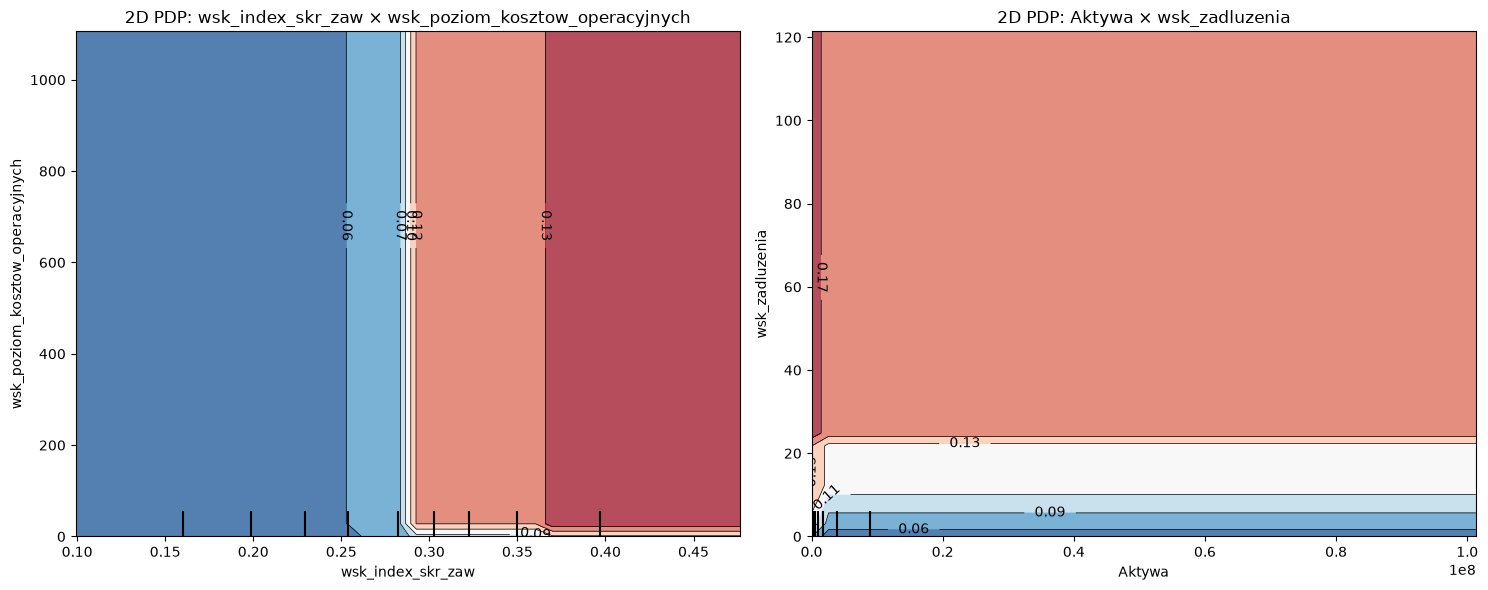

In [120]:
# Pierwsza i trzecia najsilniejsza interakcja
pary = [
    tuple(top5.iloc[0][["Cecha 1", "Cecha 2"]]),
    tuple(top5.iloc[2][["Cecha 1", "Cecha 2"]])
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, para in zip(axes, pary):

    disp = PartialDependenceDisplay.from_estimator(
        estimator=model,
        X=X_transformed,
        features=[para],
        kind="average",
        method="brute",
        response_method="predict_proba",
        grid_resolution=40,
        percentiles=(0.01, 0.99),
        ax=ax,
        contour_kw={"cmap": "RdBu_r"}
    )

    ax.set_title(f"2D PDP: {para[0]} × {para[1]}")
    ax.set_xlabel(para[0])
    ax.set_ylabel(para[1])

plt.tight_layout()
plt.show()

# ICE

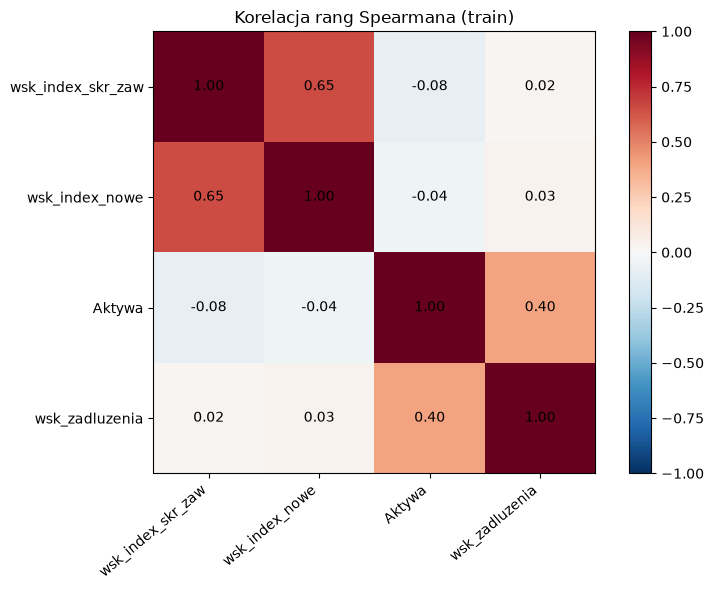

In [104]:
CECHY_KORELACJA = [
    "wsk_index_skr_zaw",
    "wsk_index_nowe",
    "Aktywa",
    "wsk_zadluzenia"
]

# Macierz korelacji rang Spearmana
korelacje = X_train[CECHY_KORELACJA].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(
    korelacje.to_numpy(),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

# Wartości korelacji w komórkach
for i in range(len(CECHY_KORELACJA)):
    for j in range(len(CECHY_KORELACJA)):
        ax.text(
            j, i,
            f"{korelacje.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=10
        )

# Nazwy zmiennych
ax.set_xticks(range(len(CECHY_KORELACJA)))
ax.set_yticks(range(len(CECHY_KORELACJA)))

ax.set_xticklabels(CECHY_KORELACJA, rotation=40, ha="right")
ax.set_yticklabels(CECHY_KORELACJA)

ax.set_title("Korelacja rang Spearmana (train)")

plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

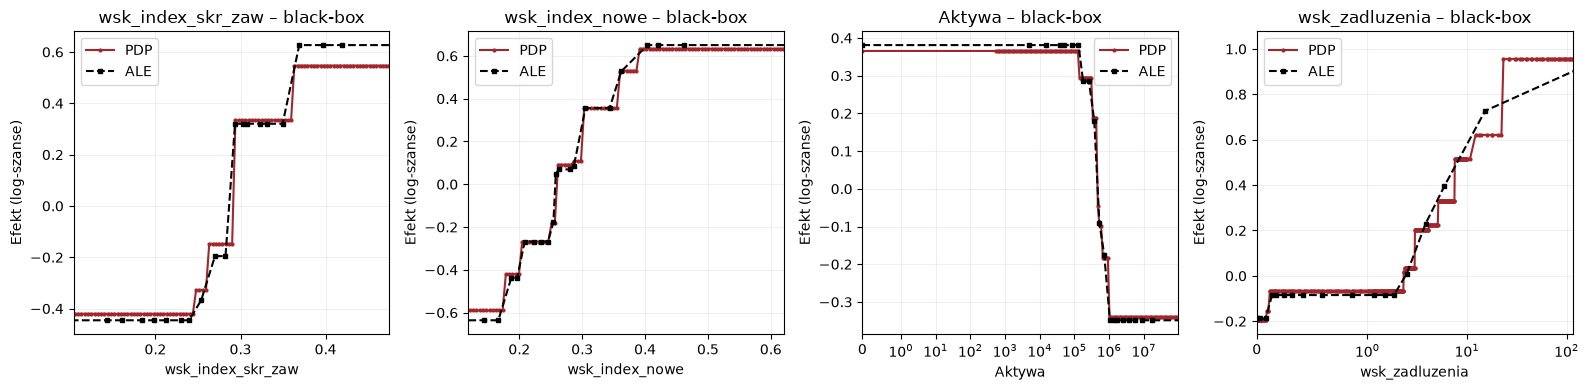

,Model,Cecha,Maks. |PDP - ALE|,Zakres ALE,Różnica / zakres
0,black-box,wsk_index_skr_zaw,0.0800,1.0724,0.0746
1,black-box,wsk_index_nowe,0.1496,1.2863,0.1163
2,black-box,Aktywa,0.0422,0.7297,0.0578
3,black-box,wsk_zadluzenia,0.1058,0.9150,0.1156


In [113]:

CECHY = [
    "wsk_index_skr_zaw",
    "wsk_index_nowe",
    "Aktywa",
    "wsk_zadluzenia"
]

MODELE = {
    "black-box": black_box
}


# Funkcja predykcyjna w log-szansach
def f_log_szanse(model, X):
    return _z(model.predict_proba(X)[:, 1])


# PDP
def pdp(model, X, cecha, siatka):
    wyniki = []

    for wartosc in siatka:
        X_temp = X.copy()
        X_temp[cecha] = wartosc

        wyniki.append(f_log_szanse(model, X_temp).mean())

    return np.asarray(wyniki)


# ALE pierwszego rzędu
def ale(model, X, cecha, K=20):
    x = X[cecha].to_numpy(dtype=float)
    ok = np.isfinite(x)

    X = X.loc[ok].copy()
    x = x[ok]

    # Przedziały kwantylowe
    granice = np.unique(
        np.quantile(x, np.linspace(0, 1, K + 1))
    )

    if len(granice) < 2:
        raise ValueError(f"Cecha {cecha} ma zbyt mało unikalnych wartości.")

    K_rzecz = len(granice) - 1

    # Przypisanie obserwacji do przedziałów
    k = np.clip(
        np.searchsorted(granice, x, side="left") - 1,
        0,
        K_rzecz - 1
    )

    X_dol = X.copy()
    X_gora = X.copy()

    X_dol[cecha] = granice[k]
    X_gora[cecha] = granice[k + 1]

    # Lokalna zmiana prognozy
    roznice = (
        f_log_szanse(model, X_gora)
        - f_log_szanse(model, X_dol)
    )

    # Liczebności przedziałów
    n_k = np.bincount(k, minlength=K_rzecz)

    # Średnia zmiana w każdym przedziale
    efekt = (
        np.bincount(
            k,
            weights=roznice,
            minlength=K_rzecz
        )
        / np.maximum(n_k, 1)
    )

    # Akumulacja efektów
    a = np.concatenate(([0], np.cumsum(efekt)))

    # Wyśrodkowanie ALE
    a -= (
        np.sum((a[:-1] + a[1:]) / 2 * n_k)
        / n_k.sum()
    )

    return granice, a, n_k


# Wyśrodkowanie PDP względem rozkładu cechy
def pdp_wysrodkowane(model, X, cecha, siatka):
    p = pdp(model, X, cecha, siatka)

    x = X[cecha].dropna().to_numpy()

    return p - np.interp(x, siatka, p).mean()


# Siatka PDP
def przygotuj_siatke(X, cecha):
    x = X[cecha].dropna()
    xmin, xmax = x.min(), x.max()

    if cecha == "Aktywa":
        dodatnie = x[x > 0]

        siatka = np.geomspace(
            dodatnie.min(),
            dodatnie.max(),
            120
        )

        if xmin <= 0:
            siatka = np.concatenate(([xmin, 0], siatka))

    elif cecha == "wsk_zadluzenia":
        dodatnie = x[x > 0]

        siatka = [
            np.geomspace(
                dodatnie.min(),
                dodatnie.max(),
                120
            ),
            np.linspace(
                xmin,
                min(10, xmax),
                150
            ),
            np.linspace(xmin, xmax, 100)
        ]

        # Progi funkcji zawiasowej
        przygotowanie = regresja_logistyczna.named_steps[
            "przygotowanie_cech"
        ]

        kolumny, informacje = przygotowanie.kolumny_niemonotoniczne_

        for kolumna, informacja in zip(kolumny, informacje):
            if kolumna == cecha:
                progi = [
                    float(informacja[1]),
                    float(informacja[2])
                ]

                for prog in progi:
                    if xmin <= prog <= xmax:
                        siatka.append(
                            np.linspace(
                                max(xmin, prog - 1),
                                min(xmax, prog + 1),
                                80
                            )
                        )
                        siatka.append(np.array([prog]))

        siatka = np.concatenate(siatka)

    else:
        siatka = np.linspace(xmin, xmax, 120)

    return np.unique(np.clip(siatka, xmin, xmax))


# Wykresy i porównanie
roznice = []

fig, axes = plt.subplots(
    1, len(CECHY),
    figsize=(16,4)
)



for nr_cechy, cecha in enumerate(CECHY):
    ax = axes[nr_cechy]

    # ALE
    granice, a, n_k = ale(
        model,
        X_test,
        cecha,
        K=20
    )

    # PDP
    siatka = przygotuj_siatke(X_test, cecha)

    p = pdp_wysrodkowane(
        model,
        X_test,
        cecha,
        siatka
    )

    # Wykres PDP
    ax.plot(
        siatka,
        p,
        "o-",
        ms=2,
        linewidth=1.5,
        color=KOL[nazwa],
        label="PDP"
    )

    # Wykres ALE
    ax.plot(
        granice,
        a,
        "s--",
        ms=3,
        linewidth=1.5,
        color="black",
        label="ALE"
    )

    # Porównanie ALE i PDP na wspólnych punktach
    p_na_granicach = np.interp(
        granice,
        siatka,
        p
    )

    # Zakres 1–99 percentyla
    x = X_test[cecha].dropna()
    lo, hi = np.percentile(x, [1, 99])

    maska = (
        (granice >= lo)
        & (granice <= hi)
    )

    if maska.any():
        maks_roznica = np.max(
            np.abs(p_na_granicach[maska] - a[maska])
        )

        zakres_ale = np.ptp(a[maska])

        udzial_roznicy = (
            maks_roznica / zakres_ale
            if zakres_ale > 0
            else np.nan
        )
    else:
        maks_roznica = np.nan
        zakres_ale = np.nan
        udzial_roznicy = np.nan

    roznice.append({
        "Model": nazwa,
        "Cecha": cecha,
        "Maks. |PDP - ALE|": maks_roznica,
        "Zakres ALE": zakres_ale,
        "Różnica / zakres": udzial_roznicy
    })

    # Formatowanie
    ax.set_title(f"{cecha} – {nazwa}")
    ax.set_xlabel(cecha)
    ax.set_ylabel("Efekt (log-szanse)")
    ax.grid(alpha=0.2)
    ax.legend()

    if cecha in ["Aktywa", "wsk_zadluzenia"]:
        ax.set_xscale("symlog", linthresh=1)

    if lo < hi:
        ax.set_xlim(lo, hi)


plt.tight_layout()
plt.show()


# Tabela różnic
tabela_roznic = pd.DataFrame(roznice)

display(
    tabela_roznic.round(4)
)

WNIOSEK: PDP pokrywa się z ALE, więc wnioski z PDP można wziąć za wiarygodne.

# Ważność kolumn

In [137]:
# 1. Przygotowanie danych
model = black_box.named_steps["classifier"]

feature_names = black_box.named_steps[
    "przygotowanie_cech"
].kolumny_wynikowe_

X_tr = pd.DataFrame(
    black_box[:-1].transform(X_train),
    columns=feature_names,
    index=X_train.index
)

X_te = pd.DataFrame(
    black_box[:-1].transform(X_test),
    columns=feature_names,
    index=X_test.index
)

# 2. Permutation importance – spadek AUC
perm = permutation_importance(
    model,
    X_te,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=2137,
    n_jobs=-1
)

waznosc_perm = perm.importances_mean

# 3. Drop-column importance – spadek AUC
auc_pelny = roc_auc_score(
    y_test,
    model.predict_proba(X_te)[:, 1]
)

waznosc_drop = []

for kolumna in feature_names:
    model_bez = clone(model)

    model_bez.fit(
        X_tr.drop(columns=kolumna),
        y_train
    )

    auc_bez = roc_auc_score(
        y_test,
        model_bez.predict_proba(
            X_te.drop(columns=kolumna)
        )[:, 1]
    )

    waznosc_drop.append(auc_pelny - auc_bez)

# 4. Średnie bezwzględne SHAP
wartosci_shap = np.asarray(shap_values.values)

if wartosci_shap.ndim == 3:
    wartosci_shap = wartosci_shap[:, :, 1]

if wartosci_shap.shape != X_te.shape:
    raise ValueError(
        "Wartości SHAP muszą odpowiadać X_test "
        "pod względem liczby obserwacji i cech."
    )

waznosc_shap = np.abs(wartosci_shap).mean(axis=0)
znak_shap = np.where(wartosci_shap.mean(axis=0) >= 0, "+", "-")

# 5. Tabela wszystkich metryk
tabela = pd.DataFrame({
    "permutacyjna": waznosc_perm,
    "drop-column": waznosc_drop,
    "średnie |SHAP|": waznosc_shap,
    "znak SHAP": znak_shap
}, index=feature_names)

# 6. Rankingi dla wszystkich cech
for kolumna in [
    "permutacyjna",
    "drop-column",
    "średnie |SHAP|"
]:
    tabela[f"ranga: {kolumna}"] = (
        tabela[kolumna]
        .rank(ascending=False, method="min")
        .astype(int)
    )

# 7. Sortowanie według SHAP
tabela = tabela.sort_values(
    "średnie |SHAP|",
    ascending=False
)

# 8. Wyświetlenie TOP 10
print("Liczone na zbiorze testowym, ranking według średnich wartości bezwzględnych SHAP:")
display(
    tabela.head(10).style.format({
        "permutacyjna": "{:.4f}",
        "drop-column": "{:.4f}",
        "średnie |SHAP|": "{:.4f}"
    })
)

Liczone na zbiorze testowym, ranking według średnich wartości bezwzględnych SHAP:


,permutacyjna,drop-column,średnie |SHAP|,znak SHAP,ranga: permutacyjna,ranga: drop-column,ranga: średnie |SHAP|
wsk_index_skr_zaw,0.0494,0.0190,0.4023,-,1,1,1
wsk_index_nowe,0.0413,-0.0055,0.3691,-,2,43,2
Aktywa,0.0004,-0.0036,0.2936,-,22,40,3
wsk_zadluzenia,0.0318,-0.0041,0.2161,-,3,41,4
wsk_index_aktywne,0.0048,0.0052,0.1530,-,5,3,5
wsk_pokrycie_zob_kr_gotowkowe_1,0.0011,0.0064,0.1214,-,14,2,6
wsk_poziom_kosztow_operacyjnych,-0.0037,-0.0084,0.1111,-,43,44,7
wsk_sytuacji_fin,0.0004,-0.0006,0.0934,-,21,35,8
wsk_struktura_kap_wlasnego_s_2,0.0066,0.0016,0.0916,-,4,13,9
wsk_ebitda_zobowiazan_odsetki_4,0.0004,-0.0006,0.0757,-,20,34,10


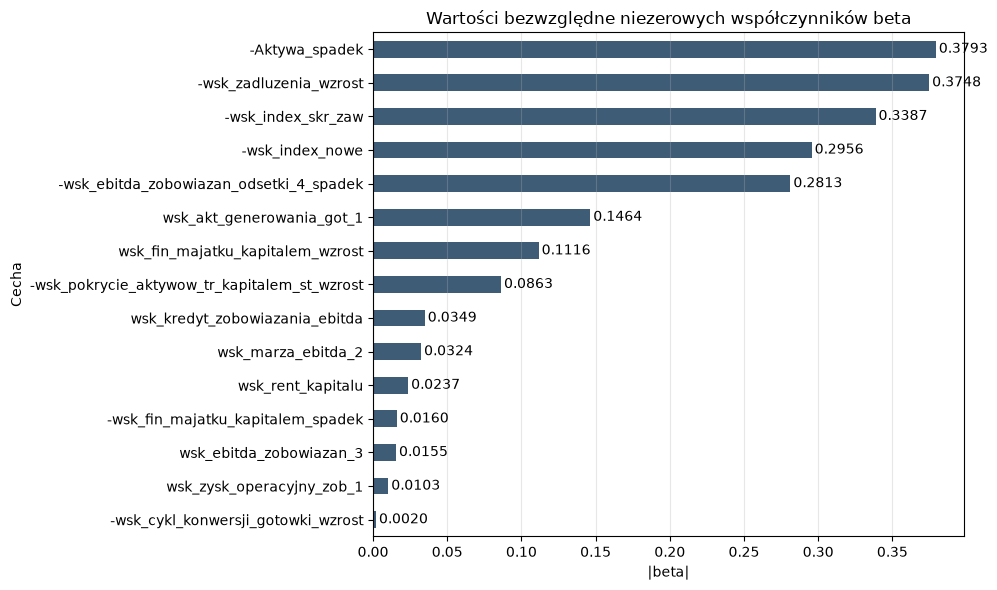

In [129]:
# seria: nazwa cechy -> |beta|
beta_abs = pd.Series(
    [abs(x) for x in betas_niezerowe],
    index=kolumny_niezerowe
).sort_values(ascending=True)   # rosnąco, żeby największe były na górze w barh

plt.figure(figsize=(10, 6))
ax = beta_abs.plot.barh(color=KOL["logit"])

ax.set_title("Wartości bezwzględne niezerowych współczynników beta")
ax.set_xlabel("|beta|")
ax.set_ylabel("Cecha")
ax.grid(axis="x", alpha=0.3)

# podpisy z wartościami
for i, v in enumerate(beta_abs):
    ax.text(v + 0.002, i, f"{v:.4f}", va="center")

plt.tight_layout()
plt.show()

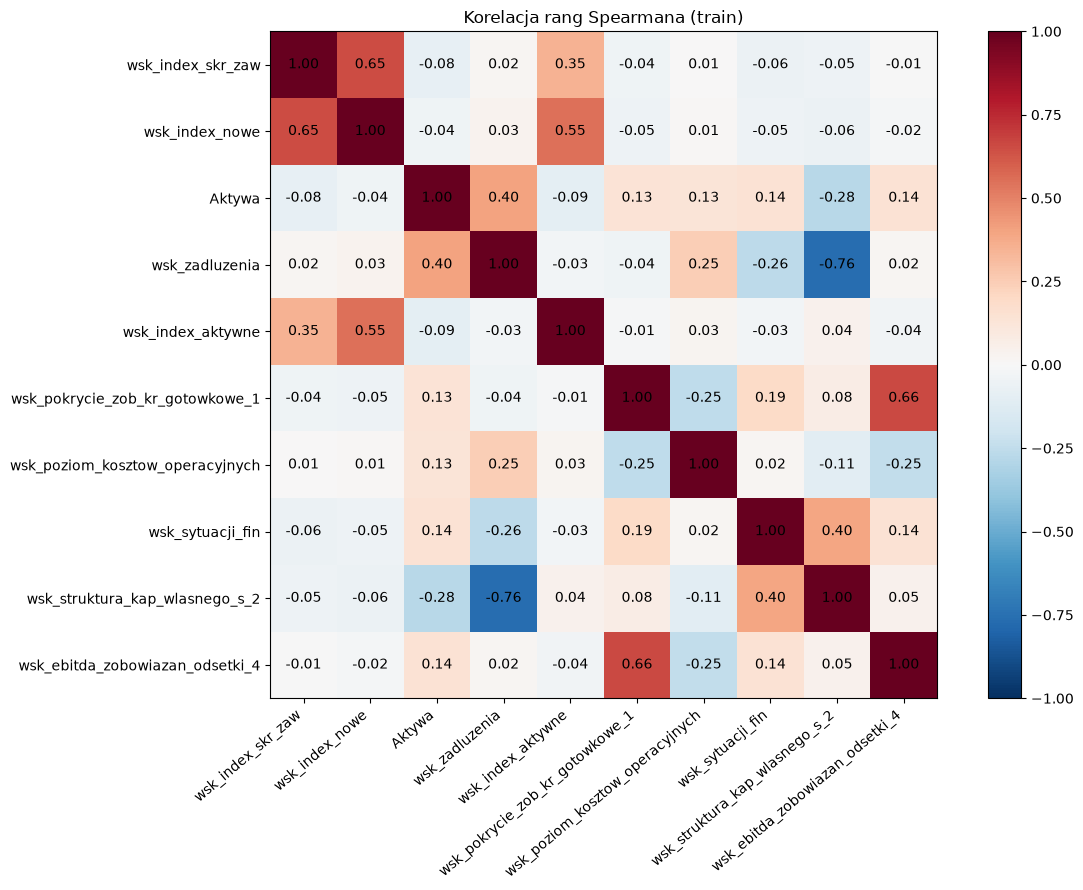

In [146]:
#korelacj rang Spearmana 10 najwyzszych cech z tabela
wybrane_cechy = tabela.head(10).index.to_list()
kor = X_train[wybrane_cechy].corr(method="spearman")
fig, ax = plt.subplots(figsize=(12, 9))

im = ax.imshow(
    kor.to_numpy(),
    cmap="RdBu_r",
    vmin=-1,
    vmax=1
)

# Wartości korelacji w komórkach
for i in range(len(wybrane_cechy)):
    for j in range(len(wybrane_cechy)):
        ax.text(
            j, i,
            f"{kor.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=10
        )

# Nazwy zmiennych
ax.set_xticks(range(len(wybrane_cechy)))
ax.set_yticks(range(len(wybrane_cechy)))

ax.set_xticklabels(wybrane_cechy, rotation=40, ha="right")
ax.set_yticklabels(wybrane_cechy)

ax.set_title("Korelacja rang Spearmana (train)")

plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

In [148]:

# 1. Grupy na podstawie korelacji Spearmana
GRUPY = {
    "Indeksy branżowe": [
        "wsk_index_skr_zaw",
        "wsk_index_nowe",
        "wsk_index_aktywne"
    ],
    "Zadłużenie i kapitał": [
        "wsk_zadluzenia",
        "wsk_struktura_kap_wlasnego_s_2"
    ],
    "Pokrycie zobowiązań": [
        "wsk_pokrycie_zob_kr_gotowkowe_1",
        "wsk_ebitda_zobowiazan_odsetki_4"
    ]
}

# 2. Przygotowanie danych
model = black_box.named_steps["classifier"]

feature_names = black_box.named_steps[
    "przygotowanie_cech"
].kolumny_wynikowe_

X_tr = pd.DataFrame(
    black_box[:-1].transform(X_train),
    columns=feature_names,
    index=X_train.index
)

X_te = pd.DataFrame(
    black_box[:-1].transform(X_test),
    columns=feature_names,
    index=X_test.index
)

# Sprawdzenie dostępności cech
for nazwa, grupa in GRUPY.items():
    brakujace = set(grupa) - set(X_te.columns)
    if brakujace:
        raise ValueError(f"{nazwa}: brak cech {brakujace}")

# 3. Bazowe AUC
auc_pelny = roc_auc_score(
    y_test,
    model.predict_proba(X_te)[:, 1]
)

# 4. Permutation importance pojedynczych cech
perm = permutation_importance(
    model,
    X_te,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=2137,
    n_jobs=-1
)

waznosc_perm = pd.Series(
    perm.importances_mean,
    index=feature_names
)

# 5. Drop-column importance
def drop_column(grupa):
    model_bez = clone(model)

    model_bez.fit(
        X_tr.drop(columns=grupa),
        y_train
    )

    auc_bez = roc_auc_score(
        y_test,
        model_bez.predict_proba(
            X_te.drop(columns=grupa)
        )[:, 1]
    )

    return auc_pelny - auc_bez


# Indywidualne drop-column (liczone tylko raz na cechę)
wszystkie_cechy = list(dict.fromkeys(
    cecha
    for grupa in GRUPY.values()
    for cecha in grupa
))

waznosc_drop = pd.Series({
    cecha: drop_column([cecha])
    for cecha in wszystkie_cechy
})


# 6. Grupowa permutation importance
def permutacja_grupowa(grupa, n_repeats=5, seed=2137):
    rng = np.random.default_rng(seed)
    wyniki_auc = []

    for _ in range(n_repeats):
        Xp = X_te.copy()

        # Ta sama permutacja dla całej grupy
        indeksy = rng.permutation(len(X_te))

        Xp[grupa] = X_te[grupa].to_numpy()[indeksy]

        auc = roc_auc_score(
            y_test,
            model.predict_proba(Xp)[:, 1]
        )

        wyniki_auc.append(auc)

    return auc_pelny - np.mean(wyniki_auc)


# 7. Porównanie dla wszystkich grup
wyniki = []

for nazwa, grupa in GRUPY.items():

    wyniki.append({
        "Grupa": nazwa,
        "Metoda": "Cała grupa naraz",
        "Permutacyjna": permutacja_grupowa(grupa),
        "Drop-column": drop_column(grupa)
    })

    wyniki.append({
        "Grupa": nazwa,
        "Metoda": "Suma pojedynczych cech",
        "Permutacyjna": waznosc_perm[grupa].sum(),
        "Drop-column": waznosc_drop[grupa].sum()
    })

tabela_grup = pd.DataFrame(wyniki).set_index(
    ["Grupa", "Metoda"]
)

print(f"Bazowe AUC: {auc_pelny:.4f}")
display(tabela_grup.round(4))

Bazowe AUC: 0.7958


Permutacyjna  Drop-column
Grupa                Metoda                                           
Indeksy branżowe     Cała grupa naraz              0.1232       0.0455
                     Suma pojedynczych cech        0.0955       0.0187
Zadłużenie i kapitał Cała grupa naraz              0.0322      -0.0028
                     Suma pojedynczych cech        0.0384      -0.0026
Pokrycie zobowiązań  Cała grupa naraz              0.0005       0.0016
                     Suma pojedynczych cech        0.0015       0.0059

WNIOSKI: 

In [151]:
#Porównanie interakcji zaproponowanych przez SHAP z statystyką H
# Model XGBoost
model = black_box.named_steps["classifier"]

# Funkcja predykcyjna zwracająca log-szanse
def f(X):
    return model.predict(X, output_margin=True)


# 1. Wybór pierwszej i trzeciej interakcji z TOP 5
para_1 = tuple(top5.iloc[0][["Cecha 1", "Cecha 2"]])
para_3 = tuple(top5.iloc[2][["Cecha 1", "Cecha 2"]])

# 2. Para kontrolna - najsłabsza interakcja z rankingu SHAP
para_kontrolna = tuple(
    ranking.sort_values("Siła interakcji")
    .iloc[0][["Cecha 1", "Cecha 2"]]
)

PARY = {
    "Interakcja 1": para_1,
    "Interakcja 3": para_3,
    "Kontrolna": para_kontrolna
}

# 3. Dwie rozłączne próby ze zbioru testowego
n = min(120, len(X_transformed) // 2)

rng = np.random.default_rng(2137)
indeksy = rng.permutation(len(X_transformed))

PROBY = {
    "Próba 1": X_transformed.iloc[indeksy[:n]].copy(),
    "Próba 2": X_transformed.iloc[indeksy[n:2*n]].copy()
}

# 4. Statystyka H dla każdej pary i próby
wyniki = []

for nazwa_pary, (j, k) in PARY.items():
    for nazwa_proby, X_probka in PROBY.items():

        H, RMS = h_statistic(
            f,
            X_probka,
            j,
            k
        )

        wyniki.append({
            "Para": nazwa_pary,
            "Cecha 1": j,
            "Cecha 2": k,
            "Próba": nazwa_proby,
            "n": len(X_probka),
            "H": H,
            "RMS": RMS
        })

wyniki_H = pd.DataFrame(wyniki)

display(wyniki_H.round(4))

,Para,Cecha 1,Cecha 2,Próba,n,H,RMS
0,Interakcja 1,wsk_index_skr_zaw,wsk_poziom_kosztow_operacyjnych,Próba 1,120,0.1821,0.0768
1,Interakcja 1,wsk_index_skr_zaw,wsk_poziom_kosztow_operacyjnych,Próba 2,120,0.1832,0.0771
2,Interakcja 3,Aktywa,wsk_zadluzenia,Próba 1,120,0.1911,0.0775
3,Interakcja 3,Aktywa,wsk_zadluzenia,Próba 2,120,0.1833,0.0714
4,Kontrolna,wsk_index_skr_zaw,wsk_fin_majatku_kapitalem,Próba 1,120,0.0000,0.0000
5,Kontrolna,wsk_index_skr_zaw,wsk_fin_majatku_kapitalem,Próba 2,120,0.0000,0.0000


# Case study